# Week 3 — Task 3: Build & Evaluate a Machine Learning Model
**Dataset:** cleaned Titanic data from Week 2 (`titanic_week2_cleaned.csv`, 773 rows x 12 columns). Original source: https://github.com/mwaskom/seaborn-data

## 1. Problem statement
**Binary classification:** predict whether a Titanic passenger survived (`survived` = 1) or died (0) from their ticket class, sex, age, family situation, fare and port of embarkation.

## 2–3. Input features (X) and target (y)

In [1]:
import pandas as pd, numpy as np, joblib
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score, roc_curve)
sns.set_theme(style="whitegrid")
%matplotlib inline

df = pd.read_csv("titanic_week2_cleaned.csv")
y = df["survived"]
X = df.drop(columns="survived")
print("Features (X):", list(X.columns))
print("Target (y): survived | class balance:", y.value_counts(normalize=True).round(3).to_dict())

Features (X): ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'family_size', 'is_alone', 'embarked_C', 'embarked_Q', 'embarked_S']
Target (y): survived | class balance: {0: 0.585, 1: 0.415}


## 4. Train / test split
Stratified 80/20 split so both sets keep the same survival rate. `random_state=42` makes it reproducible.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Survival rate train/test:", y_train.mean().round(3), y_test.mean().round(3))

Train: (618, 11) | Test: (155, 11)
Survival rate train/test: 0.416 0.413


## 5–6. Two ML algorithms and training
- **Logistic Regression** — simple, interpretable linear baseline. Needs scaled inputs, so it is wrapped in a pipeline whose scaler is fit **only on the training data** (no data leakage).
- **Random Forest** — an ensemble of decision trees that captures non-linear effects and interactions (e.g., sex x class). No scaling needed.

In [3]:
scale_cols = ["age", "fare", "family_size"]
prep = ColumnTransformer([("scale", StandardScaler(), scale_cols)], remainder="passthrough")

models = {
    "Logistic Regression": Pipeline([("prep", prep), ("clf", LogisticRegression(max_iter=1000, random_state=42))]),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=3, random_state=42),
}
for name, m in models.items():
    m.fit(X_train, y_train)
    print("Trained:", name)

Trained: Logistic Regression


Trained: Random Forest


## 7. Predictions

In [4]:
preds = {n: m.predict(X_test) for n, m in models.items()}
probas = {n: m.predict_proba(X_test)[:, 1] for n, m in models.items()}
display(pd.DataFrame({"actual": y_test.values[:10], **{n: p[:10] for n, p in preds.items()}}))

,actual,Logistic Regression,Random Forest
0,0,1,0
1,0,0,0
2,1,1,1
3,0,0,0
4,0,0,0
5,0,0,0
6,0,1,0
7,1,1,0
8,0,0,0
9,0,0,0


## 8. Evaluation (Accuracy, Precision, Recall, F1, Confusion Matrix)

In [5]:
rows = []
for n in models:
    rows.append({"model": n,
                 "accuracy": accuracy_score(y_test, preds[n]),
                 "precision": precision_score(y_test, preds[n]),
                 "recall": recall_score(y_test, preds[n]),
                 "f1": f1_score(y_test, preds[n]),
                 "roc_auc": roc_auc_score(y_test, probas[n])})
results = pd.DataFrame(rows).set_index("model").round(3)
results.to_csv("evaluation_results.csv")
display(results)
for n in models:
    print("\n" + n); print(classification_report(y_test, preds[n], target_names=["Died", "Survived"]))

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.800,0.754,0.766,0.760,0.879
Random Forest,0.819,0.909,0.625,0.741,0.873



Logistic Regression
              precision    recall  f1-score   support

        Died       0.83      0.82      0.83        91
    Survived       0.75      0.77      0.76        64

    accuracy                           0.80       155
   macro avg       0.79      0.79      0.79       155
weighted avg       0.80      0.80      0.80       155


Random Forest
              precision    recall  f1-score   support

        Died       0.78      0.96      0.86        91
    Survived       0.91      0.62      0.74        64

    accuracy                           0.82       155
   macro avg       0.85      0.79      0.80       155
weighted avg       0.84      0.82      0.81       155



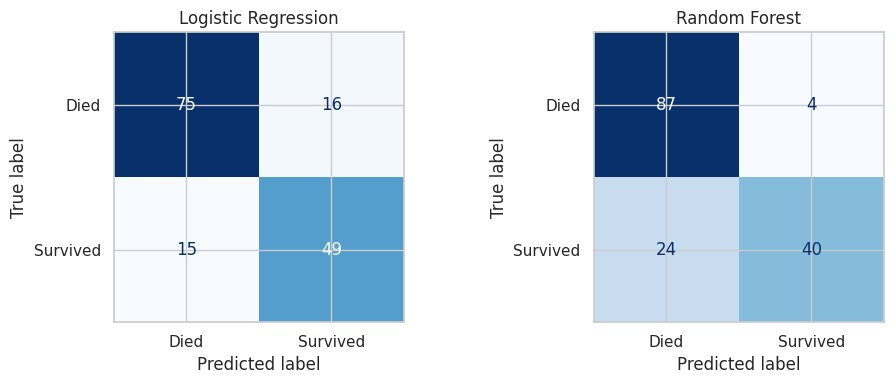

Logistic Regression: TN=75 FP=16 FN=15 TP=49
Random Forest: TN=87 FP=4 FN=24 TP=40


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, n in zip(ax, models):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[n]), display_labels=["Died", "Survived"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(n)
plt.tight_layout(); plt.savefig("cm_confusion_matrices.png", dpi=150); plt.show()
for n in models:
    tn, fp, fn, tp = confusion_matrix(y_test, preds[n]).ravel()
    print(f"{n}: TN={tn} FP={fp} FN={fn} TP={tp}")

## 9. Model comparison

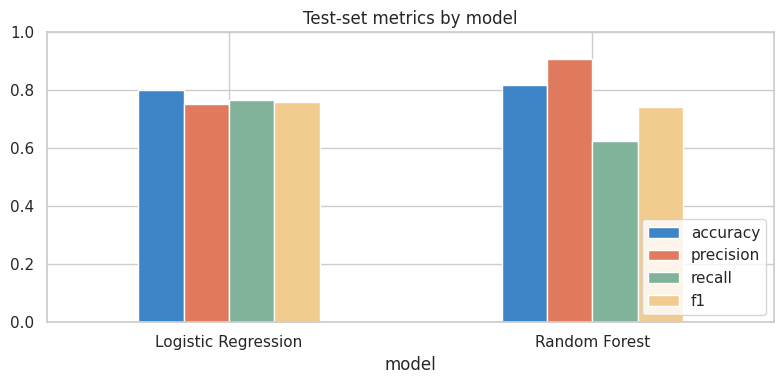

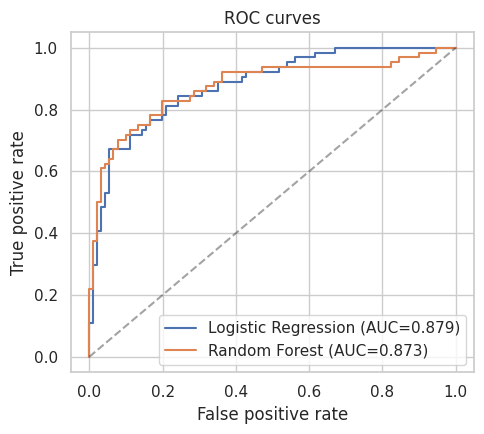

In [7]:
# Metric bar chart
results.drop(columns="roc_auc").plot.bar(figsize=(8, 4), rot=0, color=["#3d85c6", "#e07a5f", "#81b29a", "#f2cc8f"])
plt.ylim(0, 1); plt.title("Test-set metrics by model"); plt.legend(loc="lower right")
plt.tight_layout(); plt.savefig("comparison_metrics.png", dpi=150); plt.show()

# ROC curves
plt.figure(figsize=(5, 4.5))
for n in models:
    fpr, tpr, _ = roc_curve(y_test, probas[n]); plt.plot(fpr, tpr, label=f"{n} (AUC={results.loc[n,'roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=.4); plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.legend(); plt.title("ROC curves")
plt.tight_layout(); plt.savefig("comparison_roc.png", dpi=150); plt.show()

The test set has only ~155 passengers, so a single split is noisy. 5-fold stratified cross-validation on the full dataset gives a more stable comparison:

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
for n, m in models.items():
    for metric in ["accuracy", "f1"]:
        s = cross_val_score(m, X, y, cv=cv, scoring=metric)
        cv_rows.append({"model": n, "metric": metric, "mean": s.mean(), "std": s.std()})
cv_df = pd.DataFrame(cv_rows).round(3)
cv_df.to_csv("cross_validation_results.csv", index=False)
display(cv_df)

,model,metric,mean,std
0,Logistic Regression,accuracy,0.784,0.022
1,Logistic Regression,f1,0.733,0.027
2,Random Forest,accuracy,0.796,0.017
3,Random Forest,f1,0.724,0.037


## 10. Explaining the results — what drives the predictions?

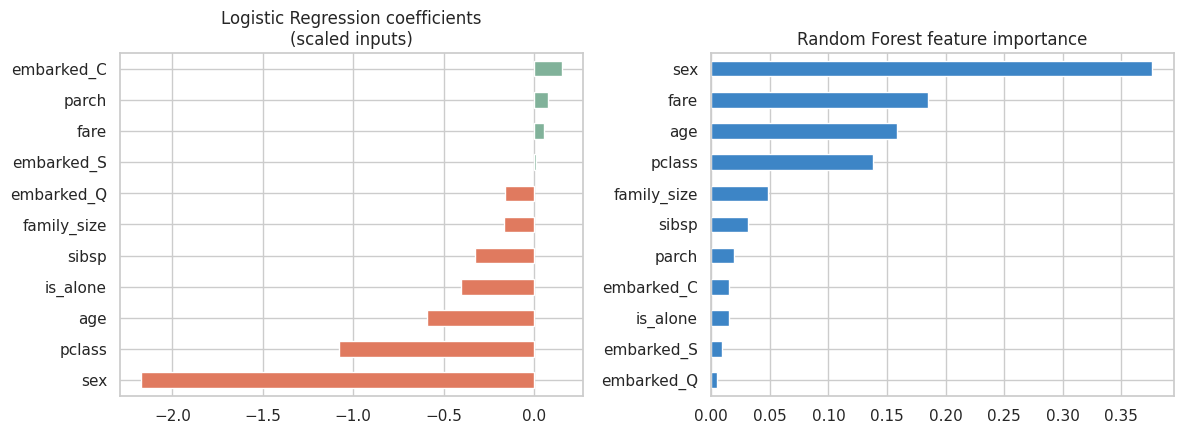

,LR_coef,RF_importance
sex,-2.172,0.376
fare,0.052,0.185
age,-0.595,0.158
pclass,-1.080,0.138
family_size,-0.169,0.049
sibsp,-0.325,0.031
parch,0.077,0.019
is_alone,-0.403,0.015
embarked_C,0.154,0.015
embarked_S,0.008,0.009


In [9]:
coef = pd.Series(models["Logistic Regression"].named_steps["clf"].coef_[0],
                 index=scale_cols + [c for c in X.columns if c not in scale_cols]).sort_values()
imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
coef.plot.barh(ax=ax[0], color=["#e07a5f" if v < 0 else "#81b29a" for v in coef]); ax[0].set_title("Logistic Regression coefficients\n(scaled inputs)")
imp.plot.barh(ax=ax[1], color="#3d85c6"); ax[1].set_title("Random Forest feature importance")
plt.tight_layout(); plt.savefig("feature_drivers.png", dpi=150); plt.show()
display(pd.DataFrame({"LR_coef": coef, "RF_importance": imp}).round(3).sort_values("RF_importance", ascending=False))

## Save trained models

In [10]:
joblib.dump(models["Logistic Regression"], "model_logistic_regression.joblib")
joblib.dump(models["Random Forest"], "model_random_forest.joblib")
print("Saved both models.")
# quick reload check
print("Reload check:", (joblib.load("model_random_forest.joblib").predict(X_test) == preds["Random Forest"]).all())

Saved both models.
Reload check: True


## Conclusion
See `Model_Comparison_and_Conclusion.md` for the full write-up. In short: Random Forest scored slightly higher accuracy on the test set (0.819 vs 0.800), but Logistic Regression has the better F1 (0.760 vs 0.741) and ROC-AUC (0.879 vs 0.873), and the cross-validated accuracy gap (0.796 vs 0.784) is within one standard deviation. The models are therefore roughly equal overall, with different error profiles: Random Forest is high-precision / low-recall (4 false positives, 24 false negatives), Logistic Regression is balanced (16 / 15). Sex, passenger class and age are the main drivers of survival.